# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [6]:
DATA_PATH = PROJECT_DIR / "data" / "wine.csv"

df = pd.read_csv(DATA_PATH)

Forma (filas, columnas): (178, 14)

--- Tipos ---
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

--- Nulos por columna ---
Sin valores nulos
Total de nulos: 0

--- Duplicados ---
Filas duplicadas: 0 (0.00%)

--- Distribución de target ---
        conteo  proporcion
target                    
0           59      0.3315
1           71      0.3989
2           48      0.2697

--- describe() ---


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


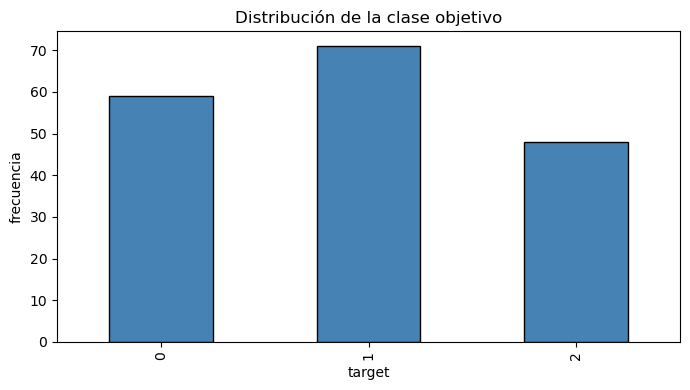

In [7]:
# Profiling básico de df

# Forma
print("Forma (filas, columnas):", df.shape)

# Tipos de datos
print("\n--- Tipos ---")
print(df.dtypes)

# Nulos por columna
print("\n--- Nulos por columna ---")
nulos = df.isna().sum()
print(nulos[nulos > 0] if nulos.any() else "Sin valores nulos")
print("Total de nulos:", int(df.isna().sum().sum()))

# Duplicados
n_dup = df.duplicated().sum()
print("\n--- Duplicados ---")
print("Filas duplicadas:", int(n_dup), f"({n_dup / len(df):.2%})")

# Distribución del target
print("\n--- Distribución de target ---")
conteo = df["target"].value_counts().sort_index()
proporcion = df["target"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"conteo": conteo, "proporcion": proporcion.round(4)}))

# Resumen estadístico
print("\n--- describe() ---")
display(df.describe().T)

# Gráfico de la distribución de clases
ax = conteo.plot(kind="bar", color="steelblue", edgecolor="black")
ax.set_title("Distribución de la clase objetivo")
ax.set_xlabel("target")
ax.set_ylabel("frecuencia")
plt.tight_layout()
plt.show()


**Conclusión de calidad:**

> Describe brevemente qué encontraste y qué decisión tomaste.

## 2. Split train/test

In [ ]:
# TODO: crea train_df (80 %) y test_df (20 %)
# Requisitos: stratify=df["target"] y random_state=RANDOM_STATE

raise NotImplementedError("TODO 3: crea el split")

In [ ]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

In [ ]:
# TODO: crea al menos tres visualizaciones usando solamente train_df

raise NotImplementedError("TODO 4: realiza el EDA")

**Hallazgos:**

1.
2.
3.

## 4. Persistencia de datos y contrato

In [ ]:
# TODO: reinicia los índices y guarda train.csv y test.csv sin el índice
# TODO: crea data_contract.json con target, features, random_state y test_size

raise NotImplementedError("TODO 5: guarda las salidas")

In [ ]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.